# 好看的雷达图

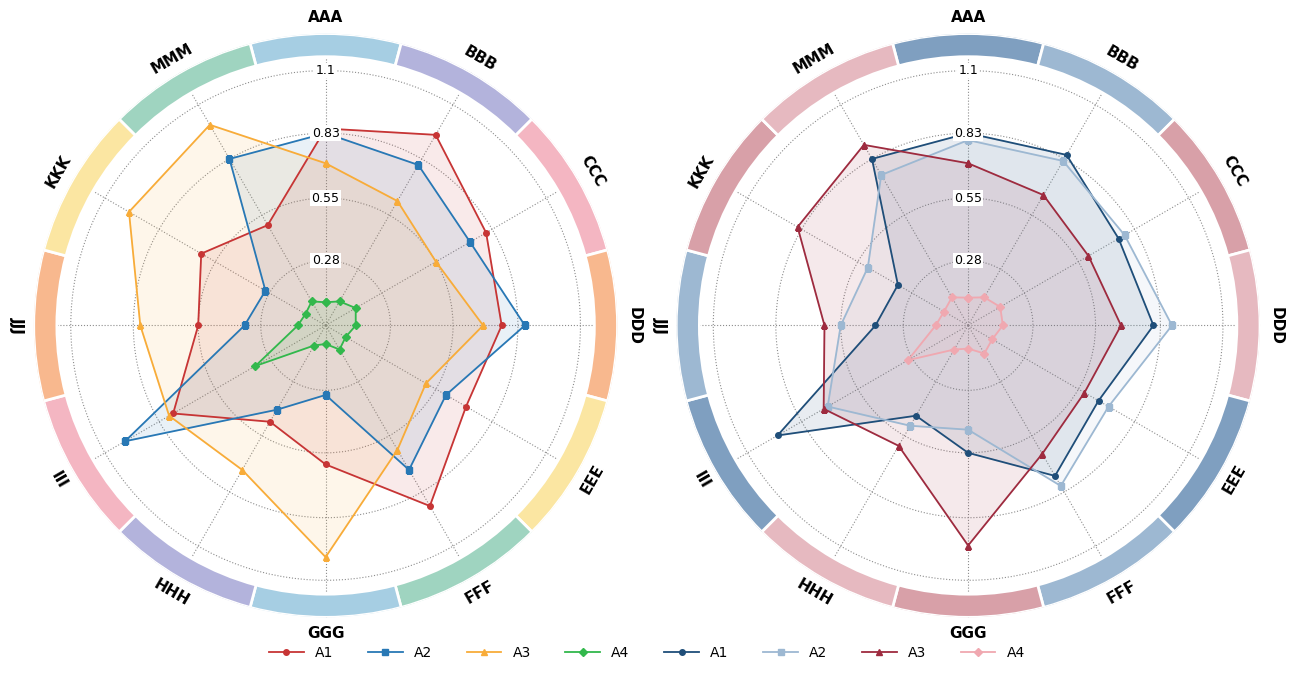

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- 基础设置 ----------
labels = ["AAA", "BBB", "CCC", "DDD", "EEE", "FFF",
          "GGG", "HHH", "III", "JJJ", "KKK", "MMM"]
N = len(labels)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False)
closed = np.r_[angles, angles[0]]          # 首尾闭合
ticks = [0.28, 0.55, 0.83, 1.1]
markers = ["o", "s", "^", "D"]
names = ["A1", "A2", "A3", "A4"]

left_colors  = ["#c73535", "#2878b5", "#f8ac39", "#32b84c"]
right_colors = ["#1f4e79", "#9db8d2", "#9e2b3f", "#f0a8b0"]
ring_left  = ["#a6cee3", "#b3b3dc", "#f4b6c2", "#f8b88e", "#fbe6a2", "#9fd4c0"]
ring_right = ["#7f9fc0", "#9db8d2", "#d8a0a8", "#e6b9c0"]

# ---------- 示例数据：每面板 4 条序列 × 12 个类别，换成你的真实值 ----------
data_left = np.array([
    [0.85, 0.95, 0.80, 0.76, 0.70, 0.90, 0.60, 0.48, 0.76, 0.55, 0.62, 0.50],
    [0.83, 0.80, 0.72, 0.86, 0.60, 0.72, 0.30, 0.42, 1.00, 0.35, 0.30, 0.83],
    [0.70, 0.62, 0.55, 0.68, 0.50, 0.62, 1.00, 0.72, 0.78, 0.80, 0.98, 1.00],
    [0.10, 0.12, 0.15, 0.13, 0.10, 0.12, 0.08, 0.10, 0.35, 0.12, 0.10, 0.12],
])

data_right = np.array([
    [0.83, 0.85, 0.75, 0.80, 0.65, 0.75, 0.55, 0.45, 0.95, 0.40, 0.35, 0.83],
    [0.80, 0.82, 0.78, 0.88, 0.70, 0.80, 0.45, 0.50, 0.70, 0.55, 0.50, 0.75],
    [0.70, 0.65, 0.60, 0.66, 0.58, 0.64, 0.95, 0.60, 0.72, 0.62, 0.85, 0.90],
    [0.12, 0.14, 0.16, 0.15, 0.12, 0.14, 0.10, 0.12, 0.30, 0.14, 0.12, 0.14],
])


def draw_radar(ax, data, colors, ring_base):
    ax.set_theta_offset(np.pi / 2)      # AAA 放在正上方
    ax.set_theta_direction(-1)          # 顺时针排列
    ax.set_ylim(0, 1.26)
    ax.set_yticks(ticks)
    ax.set_yticklabels([])              # 刻度值改为手写，保证落在顶部辐条
    ax.set_thetagrids(np.degrees(angles), labels=[])
    ax.spines["polar"].set_visible(False)
    ax.grid(True, linestyle=":", color="0.55", linewidth=0.8)

    # 外圈分类色环（极坐标 bar 即环形扇区）
    ring = (ring_base * (N // len(ring_base) + 1))[:N]
    ax.bar(angles, height=0.10, width=2 * np.pi / N, bottom=1.16,
           color=ring, edgecolor="white", linewidth=2, zorder=3)

    # 类别标签：沿切向旋转，超出 ±90° 翻转保持可读
    for ang, lab in zip(angles, labels):
        rot = ((-np.degrees(ang) + 90) % 180) - 90
        ax.text(ang, 1.33, lab, rotation=rot, rotation_mode="anchor",
                ha="center", va="center", fontsize=11, fontweight="bold",
                clip_on=False)

    # 径向刻度值：白底小标签压在顶部辐条上
    for t in ticks:
        ax.text(0, t, f"{t:g}", ha="center", va="center", fontsize=9,
                bbox=dict(facecolor="white", edgecolor="none", pad=1.0),
                zorder=6)

    # 半透明填充 + 带 marker 的折线
    for vals, c, m, nm in zip(data, colors, markers, names):
        v = np.r_[vals, vals[0]]
        ax.fill(closed, v, color=c, alpha=0.10, zorder=2)
        ax.plot(closed, v, color=c, lw=1.3, marker=m, ms=4,
                label=nm, zorder=4)


fig, axes = plt.subplots(1, 2, figsize=(13, 6.6),
                         subplot_kw=dict(projection="polar"))
draw_radar(axes[0], data_left,  left_colors,  ring_left)
draw_radar(axes[1], data_right, right_colors, ring_right)

# 两面板图例合并到底部一行
handles, labs = [], []
for ax in axes:
    h, l = ax.get_legend_handles_labels()
    handles += h
    labs += l
fig.tight_layout(rect=(0, 0.07, 1, 1))

fig.legend(handles, labs,
           loc="lower center",
           bbox_to_anchor=(0.5, 0.01),   # 图例底边贴近画布底边
           ncol=8,
           frameon=False, fontsize=10,
           handlelength=2.5, columnspacing=2.5)

# plt.savefig("radar.png", dpi=300, bbox_inches="tight")
plt.show()

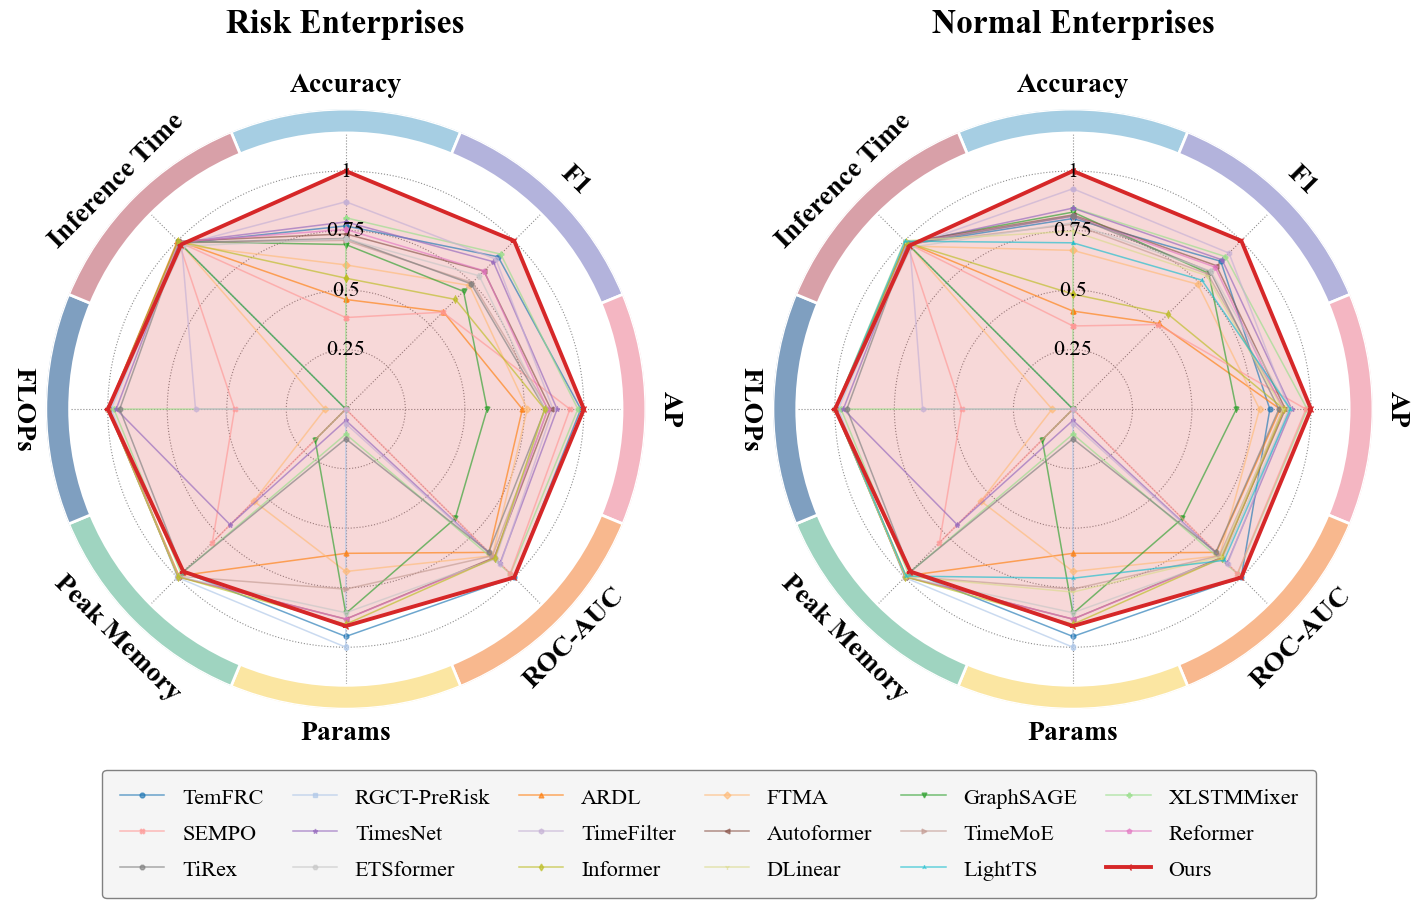

In [37]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 公共效率数据（两个口径共用；剔除 SPRF/CRI-Logit/AIGOL）
# Params, Peak Memory, FLOPs, Inference Time
# ============================================================
eff = {
    "TemFRC":      [0.1554,  17.95, 0.006167,   4.163],
    "RGCT-PreRisk":[0.0970,   9.65, 0.060691,   4.613],
    "ARDL":        [0.6081,  12.07, 0.003390,   1.686],
    "FTMA":        [0.5093, 123.66, 3.654652,   5.747],
    "GraphSAGE":   [0.2806, 215.18, 4.004727,   2.480],
    "XLSTMMixer":  [1.2570,  15.14, 0.107181, 165.245],
    "SEMPO":       [1.3933,  61.72, 2.135948,   2.854],
    "TimesNet":    [1.3317,  88.34, 0.145872,   3.411],
    "TimeFilter":  [1.3142, 261.03, 1.478857,   5.744],
    "Autoformer":  [0.2500,  10.72, 0.007093,   2.222],
    "TimeMoE":     [0.4131,  11.35, 0.012931,   3.679],
    "Reformer":    [0.2502,  10.82, 0.007719,   2.879],
    "TiRex":       [1.2314,  18.33, 0.205222,   3.580],
    "ETSformer":   [0.2847,  10.89, 0.008418,   6.907],
    "Informer":    [0.2219,  10.66, 0.006810,   2.183],
    "DLinear":     [0.3972,  11.34, 0.003174,   0.510],
    "LightTS":     [0.4725,  11.71, 0.006062,   0.872],
    "Ours":        [0.2121,  18.43, 0.006368,   5.346],
}

# ============================================================
# 风险企业精度（16 个；Recall 列已按你更正后的数据替换）
# Recall, F1, AP, ROC-AUC
# ============================================================
risk_acc = {
    "XLSTMMixer":  [0.6032, 0.7099, 0.7755, 0.9725],
    "SEMPO":       [0.4311, 0.5862, 0.7604, 0.9723],
    "TimesNet":    [0.5960, 0.6939, 0.7361, 0.9629],
    "TimeFilter":  [0.6308, 0.6994, 0.7282, 0.9633],
    "Autoformer":  [0.5754, 0.6739, 0.7242, 0.9576],
    "TimeMoE":     [0.5642, 0.6492, 0.7192, 0.9560],
    "Reformer":    [0.5831, 0.6744, 0.7181, 0.9582],
    "TiRex":       [0.5676, 0.6467, 0.7134, 0.9526],
    "ETSformer":   [0.5669, 0.6638, 0.7129, 0.9589],
    "Informer":    [0.4990, 0.6134, 0.7124, 0.9581],
    "TemFRC":      [0.5891, 0.7043, 0.7810, 0.9758],
    "RGCT-PreRisk":[0.2732, 0.3796, 0.3357, 0.8215],
    "ARDL":        [0.4623, 0.5873, 0.6703, 0.9529],
    "FTMA":        [0.5219, 0.6432, 0.6797, 0.9560],
    "GraphSAGE":   [0.5570, 0.6306, 0.6035, 0.9218],
    "Ours":        [0.6838, 0.7385, 0.7869, 0.9759],
}

# ============================================================
# 正常企业精度（18 个，含 Ours）
# Recall, F1, AP, ROC-AUC
# ============================================================
normal_acc = {
    "TemFRC":      [0.9507, 0.9702, 0.9948, 0.9758],
    "RGCT-PreRisk":[0.8700, 0.9162, 0.9795, 0.8215],
    "ARDL":        [0.9115, 0.9475, 0.9956, 0.9529],
    "FTMA":        [0.9372, 0.9618, 0.9940, 0.9560],
    "GraphSAGE":   [0.9534, 0.9658, 0.9922, 0.9218],
    "XLSTMMixer":  [0.9553, 0.9719, 0.9977, 0.9725],
    "SEMPO":       [0.9052, 0.9471, 0.9976, 0.9723],
    "TimesNet":    [0.9551, 0.9707, 0.9965, 0.9629],
    "TimeFilter":  [0.9633, 0.9732, 0.9963, 0.9633],
    "Autoformer":  [0.9522, 0.9686, 0.9960, 0.9576],
    "TimeMoE":     [0.9483, 0.9655, 0.9959, 0.9560],
    "Reformer":    [0.9516, 0.9681, 0.9958, 0.9582],
    "TiRex":       [0.9518, 0.9664, 0.9955, 0.9526],
    "ETSformer":   [0.9489, 0.9666, 0.9963, 0.9589],
    "Informer":    [0.9187, 0.9509, 0.9959, 0.9581],
    "DLinear":     [0.9453, 0.9650, 0.9958, 0.9570],
    "LightTS":     [0.9404, 0.9633, 0.9964, 0.9602],
    "Ours":        [0.9708, 0.9777, 0.9980, 0.9759],
}

# ============================================================
# 组装矩阵
# ============================================================
acc_metrics = ["Accuracy", "F1", "AP", "ROC-AUC"]
eff_metrics = ["Params", "Peak Memory", "FLOPs", "Inference Time"]
metrics = acc_metrics + eff_metrics
N = len(metrics)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False)
closed = np.r_[angles, angles[0]]

# 统一模型顺序：以 eff 的键顺序为准，Ours 放最后
MODEL_ORDER = [m for m in eff.keys() if m != "Ours"] + ["Ours"]

def build(acc_dict):
    # 两个面板都按 MODEL_ORDER 排列，保证顺序一致
    models = [m for m in MODEL_ORDER if m in acc_dict and m in eff]
    acc = np.array([acc_dict[m] for m in models], dtype=float)
    ef  = np.array([eff[m] for m in models], dtype=float)
    data = np.hstack([acc, ef])
    return models, data

def minmax(x, higher_is_better):
    lo, hi = x.min(axis=0), x.max(axis=0)
    span = np.where(hi - lo == 0, 1, hi - lo)
    return (x - lo) / span if higher_is_better else (hi - x) / span

def norm_data(data, n_acc=4):
    out = data.copy()
    out[:, :n_acc] = minmax(data[:, :n_acc],  higher_is_better=True)
    out[:, n_acc:] = minmax(data[:, n_acc:],  higher_is_better=False)
    return out

models_risk, data_risk = build(risk_acc)
models_norm, data_norm = build(normal_acc)
n_risk = norm_data(data_risk)
n_norm = norm_data(data_norm)

# 统一字体和字号
plt.rcParams.update({
    "font.family": "Times New Roman",
    "font.size": 18,
    "axes.titlesize": 24,
    "legend.fontsize": 16,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# 可集中调整这些字号
LABEL_SIZE = 20       # 外圈指标名称
TICK_SIZE = 16        # 雷达图内部刻度
TITLE_SIZE = 24       # 子图标题
LEGEND_SIZE = 16      # 图例

ring_colors = [
    "#a6cee3", "#b3b3dc", "#f4b6c2", "#f8b88e",
    "#fbe6a2", "#9fd4c0", "#7f9fc0", "#d8a0a8",
]

markers = [
    "o", "s", "^", "D", "v", "P", "X", "*",
    "h", "<", ">", "p", "8", "H", "d", "1", "2", "3",
]

# 同一个模型在两个子图中使用相同的颜色和标记
palette = plt.cm.tab20(np.linspace(0, 1, len(MODEL_ORDER)))
model_colors = dict(zip(MODEL_ORDER, palette))
model_markers = {
    m: markers[i % len(markers)]
    for i, m in enumerate(MODEL_ORDER)
}


def draw(ax, models, data_n, title):
    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)

    ax.set_ylim(0, 1.26)
    ax.set_yticks([0.25, 0.5, 0.75, 1.0])
    ax.set_yticklabels([])
    ax.set_thetagrids(np.degrees(angles), labels=[])

    ax.spines["polar"].set_visible(False)
    ax.grid(True, linestyle=":", color="0.55", linewidth=0.8)

    # 外圈色带
    ax.bar(
        angles,
        height=0.10,
        width=2 * np.pi / N,
        bottom=1.16,
        color=ring_colors[:N],
        edgecolor="white",
        linewidth=2,
        zorder=3,
    )

    # 外圈指标名称
    for ang, lab in zip(angles, metrics):
        rot = ((-np.degrees(ang) + 90) % 180) - 90
        ax.text(
            ang, 1.36, lab,
            rotation=rot,
            rotation_mode="anchor",
            ha="center",
            va="center",
            fontsize=LABEL_SIZE,
            fontweight="bold",
            clip_on=False,
        )


    # 内部刻度：不设置背景框
    for t in [0.25, 0.5, 0.75, 1.0]:
        ax.text(
            0, t, f"{t:g}",
            ha="center",
            va="center",
            fontsize=TICK_SIZE,
            color="black",
            zorder=6,
        )

    # 模型曲线
    for i, model in enumerate(models):
        is_ours = model == "Ours"
        color = "#d62728" if is_ours else model_colors[model]
        values = np.r_[data_n[i], data_n[i][0]]

        # 仅填充 Ours 围成的区域
        if is_ours:
            ax.fill(
                closed,
                values,
                color=color,
                alpha=0.18,
                edgecolor="none",
                zorder=2,  # 填充位于各模型轮廓线下方
            )

        ax.plot(
            closed,
            values,
            color=color,
            linewidth=2.8 if is_ours else 1.1,
            marker=model_markers[model],
            markersize=6 if is_ours else 3.5,
            alpha=1.0 if is_ours else 0.65,
            label=model,
            zorder=5 if is_ours else 3,
        )

    ax.set_title(
        title,
        fontsize=TITLE_SIZE,
        fontweight="bold",
        pad=55,
    )


# 放大画布，为较大的字体留出空间
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 10),
    subplot_kw={"projection": "polar"},
)

draw(axes[0], models_risk, n_risk, "Risk Enterprises")
draw(axes[1], models_norm, n_norm, "Normal Enterprises")

# 合并两个子图的图例并去重
handle_map = {}
for ax in axes:
    handles, labels = ax.get_legend_handles_labels()
    for handle, label in zip(handles, labels):
        handle_map.setdefault(label, handle)

# 统一模型顺序，Ours 放最后
legend_models = [m for m in MODEL_ORDER if m in handle_map]

# 18 个模型排成 3 行 × 6 列，按行阅读，Ours 在右下角
ncol = 6
legend_order = [
    m
    for col in range(ncol)
    for m in legend_models[col::ncol]
]

fig.legend(
    [handle_map[m] for m in legend_order],
    legend_order,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.04),
    ncol=ncol,
    fontsize=LEGEND_SIZE,
    frameon=True,
    facecolor="#F5F5F5",
    edgecolor="gray",
    framealpha=1.0,
    fancybox=True,
    borderpad=0.8,
    labelspacing=0.7,
    handlelength=2.0,
    columnspacing=1.3,
)

fig.subplots_adjust(
    left=0.05,
    right=0.95,
    top=0.84,
    bottom=0.24,
    wspace=0.02,   # 原来是 0.25，减小两张子图间距
)

# 保存图片时取消注释
# fig.savefig("radar_risk_vs_normal.pdf", bbox_inches="tight")
# fig.savefig(
#     "radar_risk_vs_normal.png",
#     dpi=300,
#     bbox_inches="tight",
# )

plt.show()